In [ ]:
%pip install ucimlrepo

In [4]:
import warnings
warnings.filterwarnings("ignore")

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    StratifiedKFold
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC, SVC

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

In [5]:
dry_bean = fetch_ucirepo(id=602)

X = dry_bean.data.features
y = dry_bean.data.targets.iloc[:, 0]

df = X.copy()
df["Class"] = y

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

print("\nStatistical summary:")
display(X.describe())

print("\nMissing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())
print("Number of classes:", y.nunique())

print("\nClass distribution:")
print(y.value_counts())

Dataset shape: (13611, 17)

First five rows:


,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4,Class
0,28395,610.291,208.178117,173.888747,1.197191,0.549812,28715,190.141097,0.763923,0.988856,0.958027,0.913358,0.007332,0.003147,0.834222,0.998724,SEKER
1,28734,638.018,200.524796,182.734419,1.097356,0.411785,29172,191.272751,0.783968,0.984986,0.887034,0.953861,0.006979,0.003564,0.909851,0.998430,SEKER
2,29380,624.110,212.826130,175.931143,1.209713,0.562727,29690,193.410904,0.778113,0.989559,0.947849,0.908774,0.007244,0.003048,0.825871,0.999066,SEKER
3,30008,645.884,210.557999,182.516516,1.153638,0.498616,30724,195.467062,0.782681,0.976696,0.903936,0.928329,0.007017,0.003215,0.861794,0.994199,SEKER
4,30140,620.134,201.847882,190.279279,1.060798,0.333680,30417,195.896503,0.773098,0.990893,0.984877,0.970516,0.006697,0.003665,0.941900,0.999166,SEKER



Column names:
['Area', 'Perimeter', 'MajorAxisLength', 'MinorAxisLength', 'AspectRatio', 'Eccentricity', 'ConvexArea', 'EquivDiameter', 'Extent', 'Solidity', 'Roundness', 'Compactness', 'ShapeFactor1', 'ShapeFactor2', 'ShapeFactor3', 'ShapeFactor4', 'Class']

Data types:
Area                 int64
Perimeter          float64
MajorAxisLength    float64
MinorAxisLength    float64
AspectRatio        float64
Eccentricity       float64
ConvexArea           int64
EquivDiameter      float64
Extent             float64
Solidity           float64
Roundness          float64
Compactness        float64
ShapeFactor1       float64
ShapeFactor2       float64
ShapeFactor3       float64
ShapeFactor4       float64
Class               object
dtype: object

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13611 entries, 0 to 13610
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Area             13611 non

,Area,Perimeter,MajorAxisLength,MinorAxisLength,AspectRatio,Eccentricity,ConvexArea,EquivDiameter,Extent,Solidity,Roundness,Compactness,ShapeFactor1,ShapeFactor2,ShapeFactor3,ShapeFactor4
count,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000,13611.000000
mean,53048.284549,855.283459,320.141867,202.270714,1.583242,0.750895,53768.200206,253.064220,0.749733,0.987143,0.873282,0.799864,0.006564,0.001716,0.643590,0.995063
std,29324.095717,214.289696,85.694186,44.970091,0.246678,0.092002,29774.915817,59.177120,0.049086,0.004660,0.059520,0.061713,0.001128,0.000596,0.098996,0.004366
min,20420.000000,524.736000,183.601165,122.512653,1.024868,0.218951,20684.000000,161.243764,0.555315,0.919246,0.489618,0.640577,0.002778,0.000564,0.410339,0.947687
25%,36328.000000,703.523500,253.303633,175.848170,1.432307,0.715928,36714.500000,215.068003,0.718634,0.985670,0.832096,0.762469,0.005900,0.001154,0.581359,0.993703
50%,44652.000000,794.941000,296.883367,192.431733,1.551124,0.764441,45178.000000,238.438026,0.759859,0.988283,0.883157,0.801277,0.006645,0.001694,0.642044,0.996386
75%,61332.000000,977.213000,376.495012,217.031741,1.707109,0.810466,62294.000000,279.446467,0.786851,0.990013,0.916869,0.834270,0.007271,0.002170,0.696006,0.997883
max,254616.000000,1985.370000,738.860154,460.198497,2.430306,0.911423,263261.000000,569.374358,0.866195,0.994677,0.990685,0.987303,0.010451,0.003665,0.974767,0.999733



Missing values: 0
Duplicate rows: 68
Number of classes: 7

Class distribution:
Class
DERMASON    3546
SIRA        2636
SEKER       2027
HOROZ       1928
CALI        1630
BARBUNYA    1322
BOMBAY       522
Name: count, dtype: int64


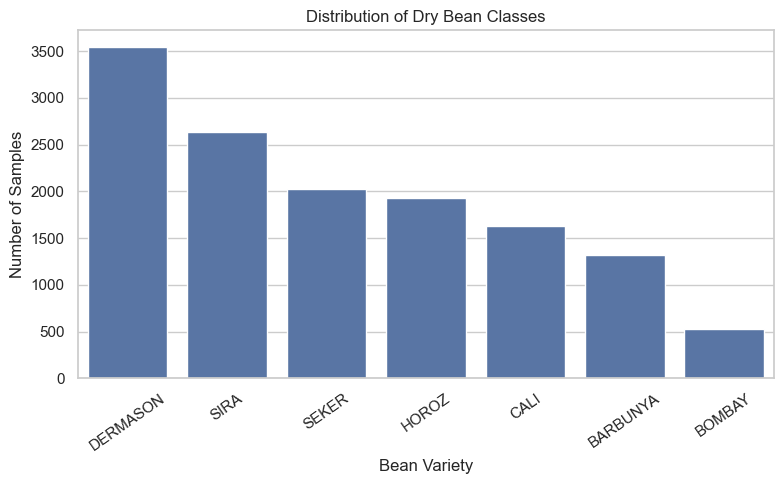

In [6]:
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x="Class", order=y.value_counts().index)
plt.title("Distribution of Dry Bean Classes")
plt.xlabel("Bean Variety")
plt.ylabel("Number of Samples")
plt.xticks(rotation=35)
plt.tight_layout()
plt.show()

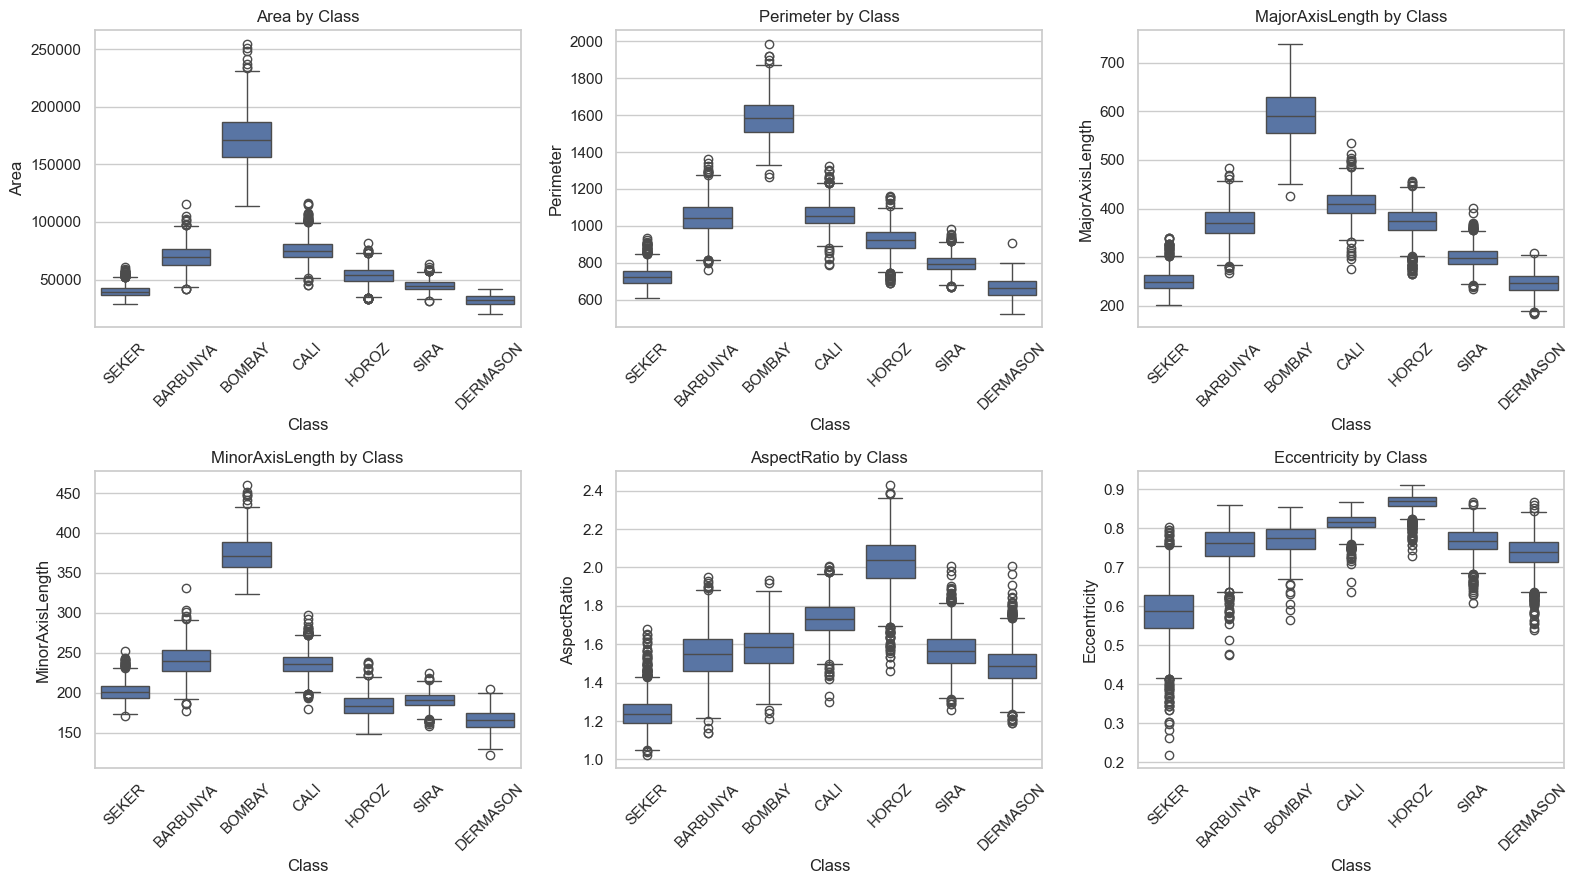

In [9]:
selected_features = [
    "Area", "Perimeter", "MajorAxisLength",
    "MinorAxisLength", "AspectRatio", "Eccentricity"
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))

for feature, ax in zip(selected_features, axes.flatten()):
    sns.boxplot(data=df, x="Class", y=feature, ax=ax)
    ax.set_title(f"{feature} by Class")
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()

In [10]:
X = X.apply(pd.to_numeric, errors="coerce")
y = y.astype(str)

print("Feature shape:", X.shape)
print("Target shape:", y.shape)
print("Missing feature values:", X.isnull().sum().sum())
print("Classes:", sorted(y.unique()))

Feature shape: (13611, 16)
Target shape: (13611,)
Missing feature values: 0
Classes: ['BARBUNYA', 'BOMBAY', 'CALI', 'DERMASON', 'HOROZ', 'SEKER', 'SIRA']


In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y
)
print("Training shape:", X_train.shape)
print("Testing shape:", X_test.shape)
print("\nTraining class proportions:")
print(y_train.value_counts(normalize=True).round(3))

Training shape: (10888, 16)
Testing shape: (2723, 16)

Training class proportions:
Class
DERMASON    0.261
SIRA        0.194
SEKER       0.149
HOROZ       0.142
CALI        0.120
BARBUNYA    0.097
BOMBAY      0.038
Name: proportion, dtype: float64


In [15]:
def evaluate_model(name, model, X_test, y_test):
    predictions = model.predict(X_test)

    results = {
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision (Macro)": precision_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "Recall (Macro)": recall_score(
            y_test, predictions, average="macro", zero_division=0
        ),
        "F1 (Macro)": f1_score(
            y_test, predictions, average="macro", zero_division=0
        )
    }

    print(f"\n========== {name} ==========")
    for metric, value in results.items():
        if metric != "Model":
            print(f"{metric}: {value:.4f}")

    print("\nClassification Report:")
    print(classification_report(y_test, predictions, zero_division=0))

    return results

In [16]:
linear_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LinearSVC(
        C=1.0,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        max_iter=20000
    ))
])

linear_model.fit(X_train, y_train)

linear_results = evaluate_model(
    "Linear SVM", linear_model, X_test, y_test
)


========== Linear SVM ==========
Accuracy: 0.9126
Precision (Macro): 0.9302
Recall (Macro): 0.9260
F1 (Macro): 0.9273

Classification Report:
              precision    recall  f1-score   support

    BARBUNYA       0.95      0.88      0.92       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.93      0.94      0.94       326
    DERMASON       0.93      0.87      0.90       709
       HOROZ       0.96      0.94      0.95       386
       SEKER       0.93      0.94      0.94       406
        SIRA       0.81      0.90      0.85       527

    accuracy                           0.91      2723
   macro avg       0.93      0.93      0.93      2723
weighted avg       0.92      0.91      0.91      2723



In [17]:
poly_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="poly",
        degree=3,
        C=1.0,
        gamma="scale",
        coef0=1.0,
        class_weight="balanced"
    ))
])

poly_model.fit(X_train, y_train)

poly_results = evaluate_model(
    "Polynomial SVM (degree=3)",
    poly_model,
    X_test,
    y_test
)


========== Polynomial SVM (degree=3) ==========
Accuracy: 0.9236
Precision (Macro): 0.9352
Recall (Macro): 0.9352
F1 (Macro): 0.9351

Classification Report:
              precision    recall  f1-score   support

    BARBUNYA       0.93      0.92      0.92       265
      BOMBAY       1.00      0.99      1.00       104
        CALI       0.94      0.94      0.94       326
    DERMASON       0.94      0.89      0.91       709
       HOROZ       0.96      0.95      0.96       386
       SEKER       0.93      0.96      0.95       406
        SIRA       0.85      0.90      0.87       527

    accuracy                           0.92      2723
   macro avg       0.94      0.94      0.94      2723
weighted avg       0.92      0.92      0.92      2723



In [18]:
poly_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="poly",
        gamma="scale",
        class_weight="balanced"
    ))
])

param_grid = {
    "classifier__C": [0.1, 1, 10],
    "classifier__degree": [2, 3],
    "classifier__coef0": [0, 1]
}

cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=RANDOM_STATE
)

grid_search = GridSearchCV(
    estimator=poly_pipeline,
    param_grid=param_grid,
    scoring="f1_macro",
    cv=cv,
    n_jobs=-1,
    refit=True,
    verbose=1
)

grid_search.fit(X_train, y_train)

best_poly_model = grid_search.best_estimator_

print("Best parameters:")
print(grid_search.best_params_)

print("\nBest cross-validation macro F1-score:")
print(round(grid_search.best_score_, 4))

Fitting 3 folds for each of 12 candidates, totalling 36 fits
Best parameters:
{'classifier__C': 10, 'classifier__coef0': 1, 'classifier__degree': 2}

Best cross-validation macro F1-score:
0.9413


In [19]:
tuned_poly_results = evaluate_model(
    "Tuned Polynomial SVM",
    best_poly_model,
    X_test,
    y_test
)



========== Tuned Polynomial SVM ==========
Accuracy: 0.9254
Precision (Macro): 0.9360
Recall (Macro): 0.9376
F1 (Macro): 0.9367

Classification Report:
              precision    recall  f1-score   support

    BARBUNYA       0.92      0.92      0.92       265
      BOMBAY       1.00      1.00      1.00       104
        CALI       0.94      0.94      0.94       326
    DERMASON       0.93      0.90      0.92       709
       HOROZ       0.96      0.95      0.96       386
       SEKER       0.94      0.96      0.95       406
        SIRA       0.86      0.89      0.88       527

    accuracy                           0.93      2723
   macro avg       0.94      0.94      0.94      2723
weighted avg       0.93      0.93      0.93      2723



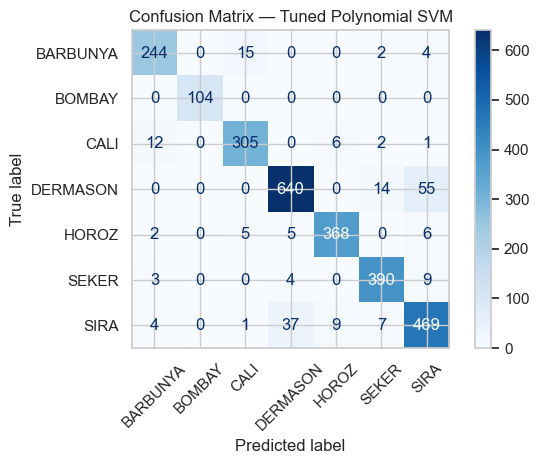

In [20]:
tuned_predictions = best_poly_model.predict(X_test)

ConfusionMatrixDisplay.from_predictions(
    y_test,
    tuned_predictions,
    labels=best_poly_model.classes_,
    display_labels=best_poly_model.classes_,
    xticks_rotation=45,
    cmap="Blues",
    values_format="d"
)

plt.title("Confusion Matrix — Tuned Polynomial SVM")
plt.tight_layout()
plt.show()

,Feature,Importance
10,Roundness,0.112769
15,ShapeFactor4,0.097844
4,AspectRatio,0.052012
12,ShapeFactor1,0.048397
3,MinorAxisLength,0.041747
1,Perimeter,0.031313
7,EquivDiameter,0.025714
14,ShapeFactor3,0.025130
11,Compactness,0.025072
0,Area,0.024606


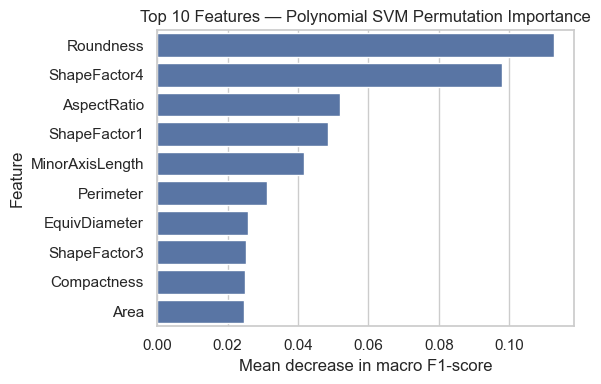

In [22]:
importance = permutation_importance(
    best_poly_model,
    X_test,
    y_test,
    scoring="f1_macro",
    n_repeats=3,
    random_state=RANDOM_STATE,
    n_jobs=-1
)

importance_df = pd.DataFrame({
    "Feature": X.columns,
    "Importance": importance.importances_mean
}).sort_values("Importance", ascending=False)

display(importance_df)

plt.figure(figsize=(6, 4))
sns.barplot(
    data=importance_df.head(10),
    x="Importance",
    y="Feature"
)

plt.title("Top 10 Features — Polynomial SVM Permutation Importance")
plt.xlabel("Mean decrease in macro F1-score")
plt.tight_layout()
plt.show()

importance_df.to_csv("dry_bean_feature_importance.csv", index=False)

In [23]:
print("Project completed successfully!")
print("\nBest Polynomial SVM parameters:")
print(grid_search.best_params_)

print("\nSaved files:")
print("- dry_bean_model_comparison.csv")
print("- dry_bean_feature_importance.csv")

Project completed successfully!

Best Polynomial SVM parameters:
{'classifier__C': 10, 'classifier__coef0': 1, 'classifier__degree': 2}

Saved files:
- dry_bean_model_comparison.csv
- dry_bean_feature_importance.csv
